<a href="https://colab.research.google.com/github/RohitRevankarDev/AML-Assignment-261100610035/blob/main/2b.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# Ensemble Learning Methods

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier
)
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:

data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Dataset shape: (569, 30)
Number of features: 30
Training samples: 455
Testing samples: 114


In [3]:

models = {
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_features="sqrt",
        random_state=42
    ),

    "AdaBoost": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=1,
            random_state=42
        ),
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    )
}

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

print("Ensemble models trained successfully.")
display(results_df.round(4))


Ensemble models trained successfully.


,Model,Accuracy,F1 Score,ROC-AUC
0,Bagging,0.9386,0.9517,0.9927
1,Random Forest,0.9561,0.9655,0.9937
2,AdaBoost,0.9561,0.9660,0.9835


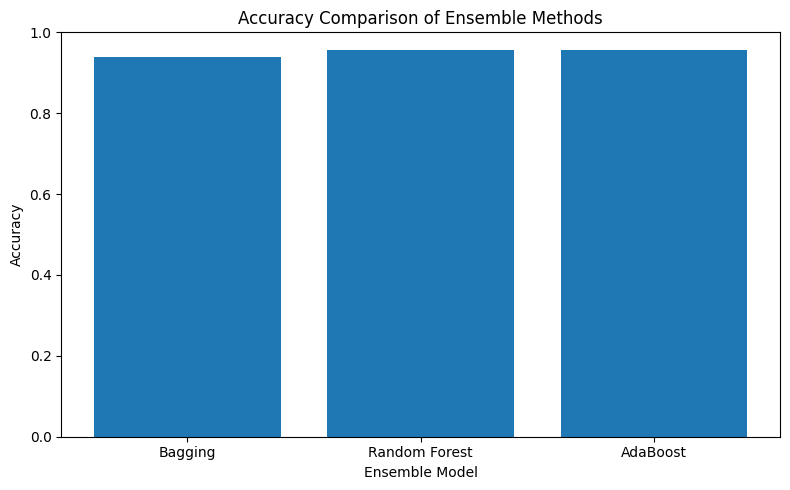

In [4]:

plt.figure(figsize=(8, 5))

plt.bar(results_df["Model"], results_df["Accuracy"])

plt.xlabel("Ensemble Model")
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison of Ensemble Methods")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


In [5]:

model_summary = pd.DataFrame({
    "Model": ["Bagging", "Random Forest", "AdaBoost"],
    "Learning Strategy": [
        "Independent trees trained on bootstrap samples",
        "Bootstrap trees with random feature selection",
        "Sequential weak learners"
    ],
    "Number of Estimators": [
        len(models["Bagging"].estimators_),
        len(models["Random Forest"].estimators_),
        len(models["AdaBoost"].estimators_)
    ]
})

display(model_summary)


,Model,Learning Strategy,Number of Estimators
0,Bagging,Independent trees trained on bootstrap samples,100
1,Random Forest,Bootstrap trees with random feature selection,100
2,AdaBoost,Sequential weak learners,100


In [6]:

print("Random Forest Classification Report:\n")

print(classification_report(
    y_test,
    predictions["Random Forest"],
    target_names=data.target_names
))


Random Forest Classification Report:

              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



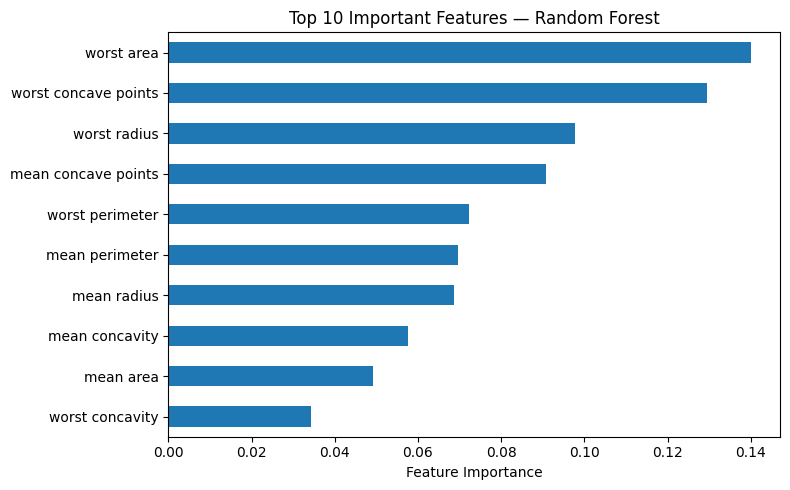

In [7]:

importance = pd.Series(
    models["Random Forest"].feature_importances_,
    index=X.columns
).sort_values(ascending=False).head(10).sort_values()

importance.plot(
    kind="barh",
    figsize=(8, 5)
)

plt.xlabel("Feature Importance")
plt.title("Top 10 Important Features — Random Forest")
plt.tight_layout()
plt.show()



## Result

Bagging, Random Forest and AdaBoost classifiers were implemented using the Breast Cancer dataset. Their performance was compared using accuracy, F1-score and ROC-AUC. A classification report and Random Forest feature-importance graph were also generated.

## Conclusion

The experiment demonstrates three ensemble learning approaches. Bagging combines independently trained models, Random Forest introduces additional feature randomness, and AdaBoost trains weak learners sequentially. Their evaluation results show how different ensemble strategies perform on the same classification task.
